# Zadanie 1 — PenDigits

**Cel:** poznaj numeryczny zbiór danych, porównaj kilka uzasadnionych metod klasyfikacji statystycznej i uczenia maszynowego oraz oceń, czy większa złożoność modelu daje istotną korzyść.

In [4]:
# Importy
import pickle
import time
from pathlib import Path            # potrzebne w komórce pobierającej dane
from zipfile import ZipFile

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from huggingface_hub import hf_hub_download
from scipy.stats import binomtest
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import GridSearchCV, GroupKFold, StratifiedKFold, cross_val_score
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

RS = 42   # ziarno losowości: za każdym razem te same wyniki
pd.set_option("display.max_columns", 20)   # pokazuj wszystkie kolumny tabel
pd.set_option("display.width", 200)

In [5]:
# Pobranie niezmienionego archiwum z oficjalnymi podziałami train/test.
DATA_DIR = Path("data/zadanie-1")
DATA_DIR.mkdir(parents=True, exist_ok=True)

archive_path = hf_hub_download(
    repo_id="AI-MED-AGH/Recruitment-Task-1",
    filename="original/pen+based+recognition+of+handwritten+digits.zip",
    repo_type="dataset",
    local_dir=DATA_DIR,
)
with ZipFile(archive_path) as archive:
    archive.extractall(DATA_DIR / "pendigits")

print(f"Dane zapisano w: {DATA_DIR / 'pendigits'}")

Dane zapisano w: data\zadanie-1\pendigits


## A — Poznanie i przygotowanie danych

Rozpoznaj zmienną docelową i cechy, sprawdź rozkład klas, braki, duplikaty oraz zakresy wartości. Pokaż krótką eksplorację danych i uzasadnij preprocessing. Zachowaj oficjalny podział danych; nie zastępuj go losowym podziałem.

In [6]:
# A1. Wczytanie oficjalnych plików train i test
# Pliki nie mają nagłówka, więc nazwy kolumn nadajemy sami:
# x1, y1, x2, y2, ..., x8, y8 (8 punktów trajektorii pióra) + cyfra.
cechy = []
for i in range(1, 9):
    cechy.append(f"x{i}")
    cechy.append(f"y{i}")
TARGET = "cyfra"

FOLDER = "data/zadanie-1/pendigits/"   # ścieżka względem folderu Zadanie-1
train = pd.read_csv(FOLDER + "pendigits.tra", header=None, names=cechy + [TARGET])
test = pd.read_csv(FOLDER + "pendigits.tes", header=None, names=cechy + [TARGET])

print("train:", train.shape, " test:", test.shape)
print(train.head())

train: (7494, 17)  test: (3498, 17)
   x1   y1  x2   y2   x3   y3   x4   y4  x5  y5   x6  y6   x7  y7   x8  y8  cyfra
0  47  100  27   81   57   37   26    0   0  23   56  53  100  90   40  98      8
1   0   89  27  100   42   75   29   45  15  15   37   0   69   2  100   6      2
2   0   57  31   68   72   90  100  100  76  75   50  51   28  25   16   0      1
3   0  100   7   92    5   68   19   45  86  34  100  45   74  23   67   0      4
4   0   67  49   83  100  100   81   80  60  60   40  40   33  20   47   0      1


In [7]:
# A2. Kto napisał każdą cyfrę?
# W archiwum są też pliki "pendigits-orig" z surowymi danymi. Przy każdej cyfrze jest tam linia:
#     .COMMENT 8 12  224
# czyli: cyfra 8, napisana przez osobę nr 12, jej 224. próbka.
# Kolejność cyfr jest taka sama jak w plikach, które wczytaliśmy wyżej.
def wczytaj_piszacych(sciezka):
    piszacy = []
    with open(sciezka) as plik:                 # otwórz plik tekstowy
        for linia in plik:                      # czytaj linijka po linijce
            if linia.startswith(".COMMENT"):
                czesci = linia.split()          # ".COMMENT 8 12 224" -> [".COMMENT", "8", "12", "224"]
                piszacy.append(int(czesci[2]))  # numer osoby to trzecia część
    return piszacy


train["piszacy"] = wczytaj_piszacych(FOLDER + "pendigits-orig.tra")
test["piszacy"] = wczytaj_piszacych(FOLDER + "pendigits-orig.tes")
print("liczba osób w train:", train["piszacy"].nunique(), " w test:", test["piszacy"].nunique())
print("ile próbek napisała każda osoba (train):", train["piszacy"].value_counts().min(),
      "-", train["piszacy"].value_counts().max())

liczba osób w train: 30  w test: 14
ile próbek napisała każda osoba (train): 247 - 250


In [8]:
# A3. Typy, braki, duplikaty
train.info()
print("braki w train:", train.isna().sum().sum(), " w test:", test.isna().sum().sum())
print("duplikaty w train:", train[cechy].duplicated().sum(), " w test:", test[cechy].duplicated().sum())
print("wiersze wspólne dla train i test:", len(train[cechy].merge(test[cechy])))

<class 'pandas.DataFrame'>
RangeIndex: 7494 entries, 0 to 7493
Data columns (total 18 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   x1       7494 non-null   int64
 1   y1       7494 non-null   int64
 2   x2       7494 non-null   int64
 3   y2       7494 non-null   int64
 4   x3       7494 non-null   int64
 5   y3       7494 non-null   int64
 6   x4       7494 non-null   int64
 7   y4       7494 non-null   int64
 8   x5       7494 non-null   int64
 9   y5       7494 non-null   int64
 10  x6       7494 non-null   int64
 11  y6       7494 non-null   int64
 12  x7       7494 non-null   int64
 13  y7       7494 non-null   int64
 14  x8       7494 non-null   int64
 15  y8       7494 non-null   int64
 16  cyfra    7494 non-null   int64
 17  piszacy  7494 non-null   int64
dtypes: int64(18)
memory usage: 1.0 MB
braki w train: 0  w test: 0
duplikaty w train: 0  w test: 0
wiersze wspólne dla train i test: 0


cyfra
0    0.104
1    0.104
2    0.104
3    0.096
4    0.104
5    0.096
6    0.096
7    0.104
8    0.096
9    0.096
Name: proportion, dtype: float64


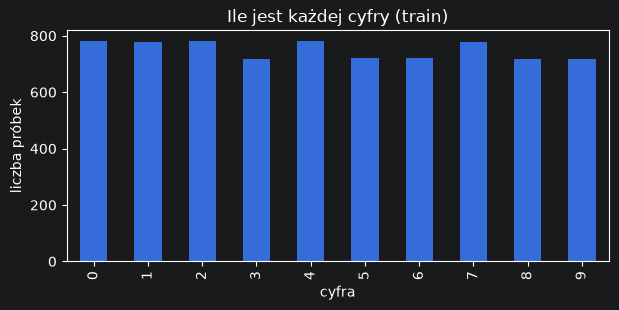

In [9]:
# A4. Rozkład klas
print(train[TARGET].value_counts(normalize=True).sort_index().round(3))
plt.figure(figsize=(7, 3))                                   # nowy, pusty wykres
train[TARGET].value_counts().sort_index().plot(kind="bar", title="Ile jest każdej cyfry (train)")
plt.xlabel("cyfra")
plt.ylabel("liczba próbek")
plt.show()

    min    max  mean   std
x1  0.0  100.0  37.4  33.3
y1  0.0  100.0  84.7  16.8
x2  0.0  100.0  40.0  26.3
y2  0.0  100.0  82.9  19.6
x3  0.0  100.0  50.9  34.9
y3  0.0  100.0  65.0  27.4
x4  0.0  100.0  51.5  30.7
y4  0.0  100.0  44.6  30.7
x5  0.0  100.0  57.1  33.7
y5  0.0  100.0  34.1  27.5
x6  0.0  100.0  61.4  37.1
y6  0.0  100.0  35.8  27.5
x7  0.0  100.0  54.7  22.6
y7  0.0  100.0  35.8  33.2
x8  0.0  100.0  46.8  41.5
y8  0.0  100.0  28.6  35.8


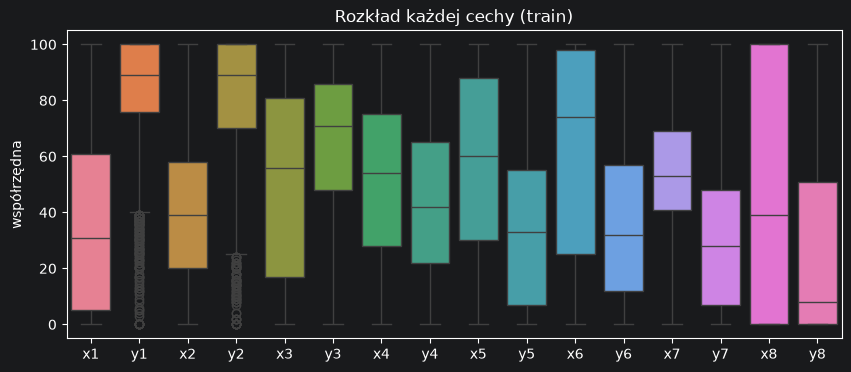

In [10]:
# A5. Zakresy wartości
print(train[cechy].describe().T[["min", "max", "mean", "std"]].round(1))
plt.figure(figsize=(10, 4))
sns.boxplot(data=train[cechy])
plt.title("Rozkład każdej cechy (train)")
plt.ylabel("współrzędna")
plt.show()

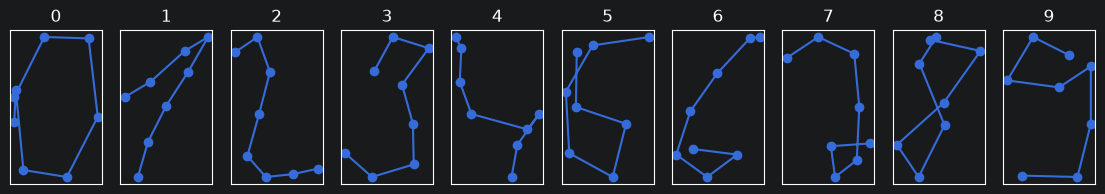

In [11]:
# A6. Jak wyglądają dane: jedna przykładowa cyfra każdego rodzaju
# Cechy to kolejne punkty pióra, więc można je narysować jako linię.
fig, axes = plt.subplots(1, 10, figsize=(14, 2))
for cyfra in range(10):
    wiersz = train[train[TARGET] == cyfra].iloc[0]          # pierwsza próbka danej cyfry
    xs = [wiersz[f"x{i}"] for i in range(1, 9)]
    ys = [wiersz[f"y{i}"] for i in range(1, 9)]
    axes[cyfra].plot(xs, ys, "o-")
    axes[cyfra].set_title(str(cyfra))
    axes[cyfra].set_xticks([])
    axes[cyfra].set_yticks([])
plt.show()

### Wnioski z eksploracji i preprocessing
- **Zmienna docelowa:** `cyfra` (0–9), więc to klasyfikacja z 10 klasami.
  **Cechy:** 16 liczb całkowitych, czyli współrzędne x i y ośmiu punktów śladu pióra.
  Autorzy zbioru przeskalowali je już do zakresu 0–100.
  Kolumna `piszacy` (numer osoby) **nie jest cechą**. Służy tylko do podziału danych
  w walidacji krzyżowej (B2).
- **Rozkład klas:** prawie równy (9,6–10,4% na cyfrę), taki sam w train i test.
  Accuracy jest więc sensowną metryką. Dodatkowo podaję macro F1 (średnie F1 wszystkich cyfr).
- **Braki:** brak. **Duplikaty:** brak, także między train i test.
- **Zakresy:** wszystkie cechy w 0–100, bez wartości niemożliwych.
- **Oficjalny podział:** train napisało 30 osób, test 14 innych osób. Nie dzielę danych na nowo.
  Test sprawdza więc, jak model radzi sobie z pismem osób, których nigdy nie widział.
- **Preprocessing:** jedynym krokiem jest `StandardScaler` dla modeli wrażliwych na skalę
  (regresja logistyczna, k-NN, SVM). Cechy mają różne rozrzuty (odchylenie od 17 do 42).
  Skaler jest w `Pipeline`, więc uczy się tylko na danych treningowych.

## B — Modelowanie

Zbuduj prosty model bazowy i porównaj go z kilkoma klasyfikatorami statystycznymi lub klasycznego uczenia maszynowego. Wykonaj dobór modeli, strojenie i sposób zapobiegania wyciekowi danych. 

In [12]:
# B1. Dane do modeli i lista kandydatów
X_train = train[cechy]
y_train = train[TARGET]
osoby_train = train["piszacy"]      # potrzebne tylko do podziału na foldy
X_test = test[cechy]
y_test = test[TARGET]

# nazwa: (pipeline, siatka hiperparametrów do sprawdzenia)
kandydaci = {
    "Baseline": (
        Pipeline([("model", DummyClassifier(strategy="most_frequent"))]),
        {},
    ),
    "Naive Bayes": (
        Pipeline([("model", GaussianNB())]),
        {},
    ),
    "LDA": (
        Pipeline([("model", LinearDiscriminantAnalysis(store_covariance=True))]),
        {},
    ),
    "Regresja logistyczna": (
        Pipeline([("skaler", StandardScaler()), ("model", LogisticRegression(max_iter=3000))]),
        {"model__C": [0.1, 1, 10]},
    ),
    "k-NN": (
        Pipeline([("skaler", StandardScaler()), ("model", KNeighborsClassifier())]),
        {"model__n_neighbors": [1, 3, 5, 7]},
    ),
    "SVM": (
        Pipeline([("skaler", StandardScaler()), ("model", SVC())]),
        {"model__C": [1, 10, 100]},
    ),
    "Las losowy": (
        Pipeline([("model", RandomForestClassifier(random_state=RS))]),
        {"model__n_estimators": [100, 300]},
    ),
}

In [13]:
# B2. Walidacja: foldy losowe czy według osób?
# Foldy losowe: próbki tej samej osoby trafiają i do części uczącej, i do sprawdzającej.
#   Model "zna" już jej charakter pisma, więc wynik wychodzi zawyżony.
# Foldy według osób (GroupKFold): każda osoba jest w całości w jednej części foldu.
#   Tak samo jest w oficjalnym teście (inne osoby niż w train), więc to uczciwsze oszacowanie.
cv_losowe = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)
cv_wg_osob = GroupKFold(n_splits=5)

knn = Pipeline([("skaler", StandardScaler()), ("model", KNeighborsClassifier(n_neighbors=1))])
wynik_losowe = cross_val_score(knn, X_train, y_train, cv=cv_losowe).mean()
wynik_wg_osob = cross_val_score(knn, X_train, y_train, cv=cv_wg_osob, groups=osoby_train).mean()
print(f"k-NN (k=1), foldy losowe:     {wynik_losowe:.4f}")
print(f"k-NN (k=1), foldy według osób: {wynik_wg_osob:.4f}")

k-NN (k=1), foldy losowe:     0.9944
k-NN (k=1), foldy według osób: 0.9672


In [14]:
# B3. Strojenie: walidacja krzyżowa według osób, tylko na zbiorze treningowym
najlepsze = {}     # nazwa -> najlepszy wyuczony pipeline
wynik_cv = {}      # nazwa -> średnia accuracy z walidacji krzyżowej
for nazwa, (pipe, siatka) in kandydaci.items():
    gs = GridSearchCV(pipe, siatka, cv=cv_wg_osob, scoring="accuracy")
    gs.fit(X_train, y_train, groups=osoby_train)   # groups mówi, która próbka jest czyja
    najlepsze[nazwa] = gs.best_estimator_
    wynik_cv[nazwa] = gs.best_score_
    print(f"{nazwa:22s} CV accuracy = {gs.best_score_:.4f}   najlepsze ustawienia: {gs.best_params_}")

Baseline               CV accuracy = 0.1041   najlepsze ustawienia: {}
Naive Bayes            CV accuracy = 0.8647   najlepsze ustawienia: {}
LDA                    CV accuracy = 0.8680   najlepsze ustawienia: {}
Regresja logistyczna   CV accuracy = 0.9365   najlepsze ustawienia: {'model__C': 10}
k-NN                   CV accuracy = 0.9681   najlepsze ustawienia: {'model__n_neighbors': 3}
SVM                    CV accuracy = 0.9777   najlepsze ustawienia: {'model__C': 10}
Las losowy             CV accuracy = 0.9670   najlepsze ustawienia: {'model__n_estimators': 300}


### Dobór modeli i ochrona przed wyciekiem danych
- **Baseline:** zawsze odpowiada najczęstszą cyfrą, około 10%. To punkt odniesienia.
- **Naive Bayes:** prosty klasyfikator statystyczny. Zakłada, że cechy są niezależne.
- **LDA:** klasyfikator statystyczny. Zakłada, że wszystkie cyfry mają taki sam kształt
  rozrzutu danych, przez co granice między klasami są liniowe.
- **Regresja logistyczna:** model liniowy. Stroję siłę regularyzacji `C`.
- **k-NN:** głosowanie najbliższych sąsiadów. Stroję liczbę sąsiadów.
- **SVM:** granice nieliniowe (jądro RBF). Stroję `C`.
- **Las losowy:** wiele drzew decyzyjnych, które głosują. Stroję liczbę drzew.

Ochrona przed wyciekiem:
1. skalowanie siedzi w `Pipeline`,
2. hiperparametry wybieram walidacją krzyżową na zbiorze treningowym,
3. foldy są według osób, bo próbki jednej osoby są do siebie podobne (pokaz w B2),
4. zbioru testowego używam tylko raz, w części C,
5. train i test nie mają wspólnych wierszy.

## C — Porównanie i wnioski

Porównaj modele na oficjalnym zbiorze testowym za pomocą odpowiednich metryk liczbowych. Uwzględnij błędy oraz praktyczny koszt modeli, np. czas uczenia i inferencji albo liczbę parametrów. Odpowiedz, czy wzrost złożoności jest wart uzyskanej poprawy.

In [15]:
# C1. Ile liczb przechowuje każdy model? (miara wielkości modelu)
def liczba_parametrow(nazwa, pipe):
    m = pipe.named_steps["model"]               # sam model, bez skalera
    if nazwa == "Regresja logistyczna":
        return m.coef_.size + m.intercept_.size             # wagi + wyrazy wolne
    if nazwa == "LDA":
        return m.means_.size + m.covariance_.size           # średnie cyfr + wspólna kowariancja
    if nazwa == "Naive Bayes":
        return m.theta_.size + m.var_.size                  # średnie i wariancje cech dla każdej cyfry
    if nazwa == "SVM":
        return m.support_vectors_.size + m.dual_coef_.size  # zapamiętane "wektory nośne" + ich wagi
    if nazwa == "k-NN":
        return X_train.size                                 # pamięta cały zbiór treningowy
    if nazwa == "Las losowy":
        return sum(drzewo.tree_.node_count for drzewo in m.estimators_)   # węzły wszystkich drzew
    return 0                                                # baseline niczego nie przechowuje

In [16]:
# C2. Metryki, czas i wielkość modeli
wiersze = []
predykcje = {}     # nazwa -> odpowiedzi modelu na teście (przydadzą się w C5)
for nazwa, pipe in najlepsze.items():
    start = time.perf_counter()
    pipe.fit(X_train, y_train)                    # ponowne uczenie tylko po to, żeby zmierzyć czas
    czas_uczenia = time.perf_counter() - start

    start = time.perf_counter()
    y_pred = pipe.predict(X_test)
    czas_predykcji = time.perf_counter() - start
    predykcje[nazwa] = y_pred

    wiersze.append({
        "model": nazwa,
        "CV accuracy": wynik_cv[nazwa],
        "test accuracy": accuracy_score(y_test, y_pred),
        "macro F1": f1_score(y_test, y_pred, average="macro"),
        "liczba błędów": (y_pred != y_test).sum(),
        "uczenie [s]": czas_uczenia,
        "predykcja [s]": czas_predykcji,
        "parametry": liczba_parametrow(nazwa, pipe),
        # pickle zamienia model na bajty (tak jak przy zapisie do pliku), więc to jego rozmiar
        "rozmiar [kB]": len(pickle.dumps(pipe)) / 1024,
    })

wyniki = pd.DataFrame(wiersze).set_index("model").sort_values("test accuracy", ascending=False)
print(wyniki.round(4))

                      CV accuracy  test accuracy  macro F1  liczba błędów  uczenie [s]  predykcja [s]  parametry  rozmiar [kB]
model                                                                                                                         
SVM                        0.9777         0.9814    0.9814             65       0.3807         0.5993      21075      171.0928
k-NN                       0.9681         0.9748    0.9750             88       0.0157         0.0918     119904      996.9268
Las losowy                 0.9670         0.9646    0.9650            124       6.3214         0.2484     181172    25590.2588
Regresja logistyczna       0.9365         0.9282    0.9285            251       0.6509         0.0059        170        2.9658
LDA                        0.8680         0.8296    0.8247            596       0.0382         0.0061        416        7.1260
Naive Bayes                0.8647         0.8225    0.8173            621       0.0139         0.0115        32

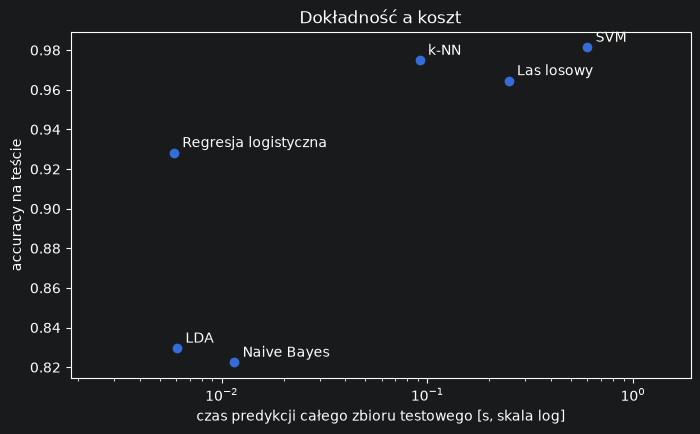

In [17]:
# C3. Wykres: dokładność a czas predykcji
bez_baseline = wyniki.drop(index="Baseline")
plt.figure(figsize=(8, 4.5))
plt.scatter(bez_baseline["predykcja [s]"], bez_baseline["test accuracy"])
for nazwa in bez_baseline.index:                       # podpis przy każdym punkcie
    punkt = (bez_baseline.loc[nazwa, "predykcja [s]"], bez_baseline.loc[nazwa, "test accuracy"])
    plt.annotate(nazwa, punkt, textcoords="offset points", xytext=(6, 4))   # napis 6 px w prawo, 4 px w górę
plt.xscale("log")                                      # czasy różnią się kilkadziesiąt razy
plt.margins(x=0.25)                                    # miejsce na podpisy
plt.xlabel("czas predykcji całego zbioru testowego [s, skala log]")
plt.ylabel("accuracy na teście")
plt.title("Dokładność a koszt")
plt.show()

Najlepszy model: SVM
              precision    recall  f1-score   support

           0      0.997     0.975     0.986       363
           1      0.973     0.986     0.980       364
           2      0.989     1.000     0.995       364
           3      0.965     0.991     0.978       336
           4      0.997     0.986     0.992       364
           5      0.979     0.985     0.982       335
           6      0.994     0.997     0.996       336
           7      0.985     0.923     0.953       364
           8      0.968     0.997     0.982       336
           9      0.965     0.976     0.970       336

    accuracy                          0.981      3498
   macro avg      0.981     0.982     0.981      3498
weighted avg      0.982     0.981     0.981      3498



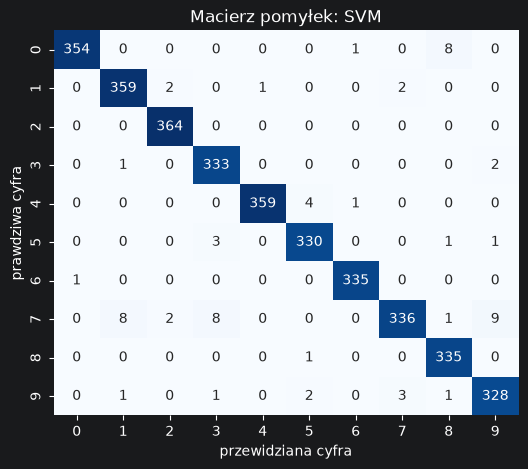

accuracy dla osób testowych: od 0.948 do 1.000, mediana 0.986


In [18]:
# C4. Błędy najlepszego modelu
najlepszy = wyniki.index[0]                       # pierwszy wiersz posortowanej tabeli
y_pred = predykcje[najlepszy]
print("Najlepszy model:", najlepszy)
print(classification_report(y_test, y_pred, digits=3))

macierz = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(macierz, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.xlabel("przewidziana cyfra")
plt.ylabel("prawdziwa cyfra")
plt.title(f"Macierz pomyłek: {najlepszy}")
plt.show()

# Dokładność najlepszego modelu dla każdej z 14 osób testowych
trafne = y_pred == y_test
na_osobe = trafne.groupby(test["piszacy"]).mean()
print(f"accuracy dla osób testowych: od {na_osobe.min():.3f} do {na_osobe.max():.3f}, "
      f"mediana {na_osobe.median():.3f}")

In [19]:
# C5. Czy przewaga najlepszego modelu nie jest przypadkiem? Test McNemara
# Liczymy tylko próbki, na których dwa modele się różnią:
#   a = najlepszy model ma rację, drugi się myli
#   b = najlepszy się myli, drugi ma rację
# Gdyby modele były równie dobre, a i b powinny być podobne (jak orły i reszki przy rzucie monetą).
# binomtest liczy, jak prawdopodobny byłby taki podział przy "rzucie monetą" (p-wartość).
# p < 0,05 -> różnica raczej nie jest przypadkiem.
dobrze_najlepszy = predykcje[najlepszy] == y_test
for nazwa in wyniki.index[1:]:                    # wszystkie modele poza najlepszym
    if nazwa == "Baseline":
        continue                                  # porównanie z baseline nic nie wnosi
    dobrze_inny = predykcje[nazwa] == y_test
    a = (dobrze_najlepszy & ~dobrze_inny).sum()   # ~ to zaprzeczenie: True <-> False
    b = (~dobrze_najlepszy & dobrze_inny).sum()
    p = binomtest(int(a), int(a + b), 0.5).pvalue
    print(f"{najlepszy} vs {nazwa:22s} a = {a:3d}, b = {b:3d}, p = {p:.2g}")

SVM vs k-NN                   a =  38, b =  15, p = 0.0022
SVM vs Las losowy             a =  79, b =  20, p = 1.8e-09
SVM vs Regresja logistyczna   a = 194, b =   8, p = 1.9e-47
SVM vs LDA                    a = 538, b =   7, p = 4.8e-149
SVM vs Naive Bayes            a = 563, b =   7, p = 2e-156


### Wnioski
(Liczby z mojego uruchomienia. Czasy zależą od komputera, reszta wychodzi zawsze tak samo.)

1. **Wszystkie modele wyraźnie biją baseline** (10,4%). Najlepszy jest SVM, 98,1% accuracy
   na teście, 65 błędów na 3498 próbek. Drugi jest k-NN (97,5%, 88 błędów), trzeci las losowy
   (96,5%, 124 błędy).
2. **Modele statystyczne i liniowe są wyraźnie słabsze:** Naive Bayes 82,3%, LDA 83,0%,
   regresja logistyczna 92,8%. Ich założenia (niezależne cechy, liniowe granice) nie pasują
   do danych, w których kolejne punkty śladu pióra są mocno ze sobą powiązane.
3. **Błędy SVM:** najtrudniejsza jest cyfra 7 (czułość 92,3%), mylona z 9, 1 i 3 (po 8–9 razy).
   Często mylone jest też 0 z 8 (8 razy): obie cyfry zaczynają się u góry i zataczają pętlę.
   Dokładność zależy od osoby: od 94,8% do 100% (mediana 98,6%) dla 14 osób testowych.
4. **Walidacja według osób była potrzebna:** foldy losowe zawyżają wynik (dla k-NN to 99,4% zamiast
   96,7%), bo model widzi w nauce próbki tej samej osoby. Foldy według osób dały wyniki bliskie
   testowi (dla SVM to 97,8% w CV, 98,1% na teście), więc wybór modelu był wiarygodny.
5. **Czy przewaga SVM jest prawdziwa?** Test McNemara: SVM vs k-NN p ≈ 0,002, vs pozostałe
   jeszcze mniej, więc różnice raczej nie są przypadkiem. Test zakłada jednak niezależne
   próbki, a próbki jednej osoby są podobne, więc te p-wartości są raczej zbyt optymistyczne.
6. **Koszt:** SVM przechowuje ok. 21 tys. liczb (ok. 170 kB). k-NN pamięta cały zbiór treningowy
   (ok. 120 tys. liczb, ok. 1 MB). Las losowy jest największy (ok. 181 tys. węzłów, ok. 25 MB),
   uczy się najdłużej i jest gorszy od SVM. Regresja logistyczna ma tylko 170 parametrów (3 kB)
   i przewiduje kilkadziesiąt razy szybciej niż SVM, ale robi prawie 4 razy więcej błędów.

**Czy wzrost złożoności jest wart poprawy?** Przejście z modelu liniowego (regresja logistyczna)
na nieliniowy (SVM) owszem jest warte, liczba błędów spada z 251 do 65, a SVM nadal jest mały i szybki
(cały zbiór testowy w ułamku sekundy). Dalszy wzrost złożoności jednak nie, las losowy jest
ok. 150 razy większy od SVM, uczy się dłużej i robi więcej błędów. Rekomenduję SVM jako
najlepszy kompromis jakości i kosztu.

## Oddanie zadania

Zapisz kod, wyniki, wykresy i krótkie uzasadnienia w tym notatniku. Podaj użyte źródła oraz narzędzia AI i upewnij się, że notatnik można uruchomić od początku do końca. Wykonaj commit po zakończeniu zadania aby znalazł się na repozytorium.

**Źródła:**
- opis zbioru `pendigits.names` i `pendigits-orig.names` (E. Alpaydin, F. Alimoglu, 1998), dołączony do archiwum z danymi,
- dokumentacja scikit-learn: `Pipeline`, `GridSearchCV`, `GroupKFold`, metryki klasyfikacji.

**Narzędzia AI:** Claude (Anthropic): pomoc przy pisaniu kodu i wyjaśnianiu bibliotek.